# 03 — Development-Only Exploratory Data Analysis

## Purpose

This notebook performs exploratory data analysis (EDA) using only the official
80% development partition of the employee resignation dataset.

The formal 20% holdout is intentionally excluded from all target-informed
exploratory analysis so that it remains independent for final evaluation.

This notebook will:

- verify the raw dataset, frozen split registry, and frozen feature contract;
- construct the 80,000-row development-only analysis dataset;
- inspect the development target distribution;
- analyze numerical and categorical feature distributions;
- compare approved predictors with `Resigned`;
- inspect numerical correlations and known feature redundancy;
- describe sensitive attributes for later fairness analysis;
- review statistical outliers without automatically removing records;
- save reproducible EDA tables and figures under `results/eda/`;
- document evidence-based modelling and preprocessing implications.

### Important boundaries

This notebook does **not**:

- train any machine-learning model;
- perform hyperparameter tuning;
- create new train/test splits or CV folds;
- inspect target relationships in the formal holdout;
- fit encoders, scalers, imputers, or category vocabularies for modelling;
- apply SMOTE or any other resampling method;
- remove records simply because they are statistical outliers;
- create a universal preprocessed dataset;
- perform final fairness evaluation;
- perform calibration, threshold selection, or retention prioritization.

All later model-specific learned preprocessing must be fitted inside the
applicable training folds.

In [1]:
# ------------------------------------------------------------
# IMPORT REQUIRED LIBRARIES
# ------------------------------------------------------------

from pathlib import Path
import hashlib
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyYAML is used to read the frozen shared feature contract.
try:
    import yaml
except ModuleNotFoundError as exc:
    raise ModuleNotFoundError(
        "PyYAML is required for this notebook. "
        "Install it in the active environment with: pip install pyyaml"
    ) from exc


# Display tables without truncating important columns during EDA.
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

print("Imports loaded successfully.")

Imports loaded successfully.


In [2]:
# ------------------------------------------------------------
# DEFINE PROJECT PATHS
# ------------------------------------------------------------

# The notebook is stored inside the notebooks/ folder,
# so ".." points to the project root.
project_root = Path("..").resolve()

# Core project inputs.
raw_data_file = (
    project_root
    / "data"
    / "raw"
    / "Extended_Employee_Performance_and_Productivity_Data.csv"
)

split_registry_file = (
    project_root
    / "data"
    / "processed"
    / "split_registry.csv"
)

feature_contract_file = (
    project_root
    / "configs"
    / "feature_contract.yaml"
)

# Prior mechanical audit outputs.
audit_results_folder = project_root / "results" / "audit"

# EDA outputs created by this notebook.
eda_results_folder = project_root / "results" / "eda"
eda_results_folder.mkdir(parents=True, exist_ok=True)


# Helper used throughout the notebook to calculate file fingerprints.
def sha256_file(file_path: Path) -> str:
    """Return the SHA-256 checksum of a file."""
    sha256 = hashlib.sha256()

    with open(file_path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()


print("Project root:", project_root)
print("Raw dataset:", raw_data_file)
print("Split registry:", split_registry_file)
print("Feature contract:", feature_contract_file)
print("EDA results folder:", eda_results_folder)

Project root: /Users/hirukaliyanage/Desktop/2Y1S/AI:ML/Project
Raw dataset: /Users/hirukaliyanage/Desktop/2Y1S/AI:ML/Project/data/raw/Extended_Employee_Performance_and_Productivity_Data.csv
Split registry: /Users/hirukaliyanage/Desktop/2Y1S/AI:ML/Project/data/processed/split_registry.csv
Feature contract: /Users/hirukaliyanage/Desktop/2Y1S/AI:ML/Project/configs/feature_contract.yaml
EDA results folder: /Users/hirukaliyanage/Desktop/2Y1S/AI:ML/Project/results/eda


In [3]:
# ------------------------------------------------------------
# LOAD AND VALIDATE THE FROZEN FEATURE CONTRACT
# ------------------------------------------------------------

# Stop immediately if the shared contract is missing.
if not feature_contract_file.exists():
    raise FileNotFoundError(
        f"Feature contract not found:\n{feature_contract_file}"
    )


# Load the YAML contract.
with open(feature_contract_file, "r", encoding="utf-8") as file:
    feature_contract = yaml.safe_load(file)


# Confirm that the contract is explicitly frozen.
contract_status = feature_contract["contract"]["status"]

if contract_status != "frozen":
    raise ValueError(
        "The shared feature contract is not marked as frozen."
    )


# Define the already-approved feature roles independently so this
# notebook can detect an accidental edit to the frozen YAML contract.
EXPECTED_TARGET_COLUMN = "Resigned"

EXPECTED_CATEGORICAL_FEATURES = [
    "Department",
    "Gender",
    "Job_Title",
    "Education_Level",
]

EXPECTED_NUMERICAL_FEATURES = [
    "Age",
    "Years_At_Company",
    "Performance_Score",
    "Monthly_Salary",
    "Work_Hours_Per_Week",
    "Projects_Handled",
    "Overtime_Hours",
    "Sick_Days",
    "Remote_Work_Frequency",
    "Team_Size",
    "Training_Hours",
    "Promotions",
    "Employee_Satisfaction_Score",
]

EXPECTED_PRIMARY_MODEL_FEATURES = (
    EXPECTED_CATEGORICAL_FEATURES
    + EXPECTED_NUMERICAL_FEATURES
)

EXPECTED_EXCLUDED_FEATURES = [
    "Employee_ID",
    "Hire_Date",
    "Resigned",
]

EXPECTED_SENSITIVE_ATTRIBUTES = [
    "Gender",
    "Age",
]


# Read the authoritative feature roles from the contract.
target_column = feature_contract["target"]["column"]

categorical_features = [
    item["name"]
    for item in feature_contract["categorical_features"]
]

numerical_features = [
    item["name"]
    for item in feature_contract["numerical_features"]
]

primary_model_features = feature_contract["primary_model_features"]

excluded_features = [
    item["column"]
    for item in feature_contract["excluded_features"]
]

sensitive_attributes = feature_contract["sensitive_attributes"]


# Verify the exact frozen feature roles, not only their counts.
if target_column != EXPECTED_TARGET_COLUMN:
    raise ValueError(
        f"Frozen target changed: {target_column}"
    )

if categorical_features != EXPECTED_CATEGORICAL_FEATURES:
    raise ValueError(
        "Frozen categorical feature list has changed."
    )

if numerical_features != EXPECTED_NUMERICAL_FEATURES:
    raise ValueError(
        "Frozen numerical/ordinal feature list has changed."
    )

if primary_model_features != EXPECTED_PRIMARY_MODEL_FEATURES:
    raise ValueError(
        "Frozen primary feature list has changed."
    )

if excluded_features != EXPECTED_EXCLUDED_FEATURES:
    raise ValueError(
        "Frozen excluded-feature list has changed."
    )

if sensitive_attributes != EXPECTED_SENSITIVE_ATTRIBUTES:
    raise ValueError(
        "Frozen sensitive-attribute list has changed."
    )


# Verify the expected shared feature counts.
if len(categorical_features) != 4:
    raise ValueError(
        f"Expected 4 categorical predictors, found {len(categorical_features)}."
    )

if len(numerical_features) != 13:
    raise ValueError(
        f"Expected 13 numerical/ordinal predictors, found {len(numerical_features)}."
    )

if len(primary_model_features) != 17:
    raise ValueError(
        f"Expected 17 primary predictors, found {len(primary_model_features)}."
    )


# Verify that excluded fields cannot accidentally enter the model feature set.
excluded_overlap = set(excluded_features).intersection(primary_model_features)

if excluded_overlap:
    raise ValueError(
        f"Excluded fields appear in the primary feature set: {excluded_overlap}"
    )


print("FEATURE CONTRACT VERIFICATION")
print("-" * 45)

print("Contract status:", contract_status)
print("Target:", target_column)
print("Categorical predictors:", len(categorical_features))
print("Numerical/ordinal predictors:", len(numerical_features))
print("Total primary predictors:", len(primary_model_features))
print("Excluded fields:", excluded_features)
print("Sensitive attributes:", sensitive_attributes)

print("\nFrozen feature contract verification: PASSED")

FEATURE CONTRACT VERIFICATION
---------------------------------------------
Contract status: frozen
Target: Resigned
Categorical predictors: 4
Numerical/ordinal predictors: 13
Total primary predictors: 17
Excluded fields: ['Employee_ID', 'Hire_Date', 'Resigned']
Sensitive attributes: ['Gender', 'Age']

Frozen feature contract verification: PASSED


In [4]:
# ------------------------------------------------------------
# VERIFY AND LOAD THE RAW DATASET AND SPLIT REGISTRY
# ------------------------------------------------------------

# These are the independently frozen project fingerprints.
# They are repeated here so an accidental edit to feature_contract.yaml
# cannot silently redefine which data files are considered valid.
FROZEN_RAW_SHA256 = (
    "2b1e07caf58e7678a780d428c1a8893a"
    "95d9c4a556134fd8e7368db5ed596cdb"
)

FROZEN_REGISTRY_SHA256 = (
    "87edc10ac38f2435c49beddbf412f9de"
    "293e3e0622558b27ffbdf31fadd7ea41"
)


# Stop if either required input file is missing.
if not raw_data_file.exists():
    raise FileNotFoundError(
        f"Raw dataset not found:\n{raw_data_file}"
    )

if not split_registry_file.exists():
    raise FileNotFoundError(
        f"Split registry not found:\n{split_registry_file}"
    )


# Read the fingerprints recorded in the frozen feature contract.
contract_raw_sha256 = feature_contract["dataset"]["sha256"]
contract_registry_sha256 = feature_contract["split_registry"]["sha256"]


# The contract itself must agree with the independently frozen values.
if contract_raw_sha256 != FROZEN_RAW_SHA256:
    raise ValueError(
        "feature_contract.yaml contains an unexpected raw dataset SHA-256."
    )

if contract_registry_sha256 != FROZEN_REGISTRY_SHA256:
    raise ValueError(
        "feature_contract.yaml contains an unexpected split-registry SHA-256."
    )


# Calculate the actual file fingerprints.
actual_raw_sha256 = sha256_file(raw_data_file)
actual_registry_sha256 = sha256_file(split_registry_file)


# Stop if either project input differs from the frozen project files.
if actual_raw_sha256 != FROZEN_RAW_SHA256:
    raise ValueError(
        "Raw dataset SHA-256 does not match the frozen project dataset."
    )

if actual_registry_sha256 != FROZEN_REGISTRY_SHA256:
    raise ValueError(
        "Split registry SHA-256 does not match the frozen project registry."
    )


# Keep these names for the final validation cell.
expected_raw_sha256 = FROZEN_RAW_SHA256
expected_registry_sha256 = FROZEN_REGISTRY_SHA256


# Load the verified raw dataset.
raw_df = pd.read_csv(raw_data_file)

# Load cv_fold as a nullable integer so holdout rows can remain <NA>.
split_registry = pd.read_csv(
    split_registry_file,
    dtype={"cv_fold": "Int64"},
)


# Verify the expected raw shape.
expected_rows = feature_contract["dataset"]["expected_rows"]
expected_columns = feature_contract["dataset"]["expected_columns"]

if raw_df.shape != (expected_rows, expected_columns):
    raise ValueError(
        f"Unexpected raw dataset shape: {raw_df.shape}. "
        f"Expected ({expected_rows}, {expected_columns})."
    )


# Verify the exact split-registry structure.
expected_registry_columns = [
    "Employee_ID",
    "partition",
    "cv_fold",
]

if split_registry.columns.tolist() != expected_registry_columns:
    raise ValueError(
        "Split registry columns do not match the frozen registry schema."
    )


# Verify all approved and excluded raw fields actually exist.
required_raw_columns = set(
    primary_model_features
    + excluded_features
)

missing_required_columns = (
    required_raw_columns
    - set(raw_df.columns)
)

if missing_required_columns:
    raise ValueError(
        f"Required raw columns are missing: {missing_required_columns}"
    )


print("INPUT FILE VERIFICATION")
print("-" * 45)

print("Raw dataset SHA-256:", actual_raw_sha256)
print("Split registry SHA-256:", actual_registry_sha256)
print("Raw dataset shape:", raw_df.shape)
print("Split registry shape:", split_registry.shape)

print("\nDataset and split registry verification: PASSED")

INPUT FILE VERIFICATION
---------------------------------------------
Raw dataset SHA-256: 2b1e07caf58e7678a780d428c1a8893a95d9c4a556134fd8e7368db5ed596cdb
Split registry SHA-256: 87edc10ac38f2435c49beddbf412f9de293e3e0622558b27ffbdf31fadd7ea41
Raw dataset shape: (100000, 20)
Split registry shape: (100000, 3)

Dataset and split registry verification: PASSED


In [5]:
# ------------------------------------------------------------
# CREATE THE DEVELOPMENT-ONLY EDA DATASET
# ------------------------------------------------------------

# Both files must contain one unique Employee_ID per record.
if raw_df["Employee_ID"].isna().any():
    raise ValueError("Raw dataset contains missing Employee_ID values.")

if raw_df["Employee_ID"].duplicated().any():
    raise ValueError("Raw dataset contains duplicate Employee_ID values.")

if split_registry["Employee_ID"].isna().any():
    raise ValueError("Split registry contains missing Employee_ID values.")

if split_registry["Employee_ID"].duplicated().any():
    raise ValueError("Split registry contains duplicate Employee_ID values.")


# Verify that both sources refer to exactly the same 100,000 employees.
if set(raw_df["Employee_ID"]) != set(split_registry["Employee_ID"]):
    raise ValueError(
        "Employee_ID membership differs between the raw data and split registry."
    )


# Merge by the stable record identifier.
# validate="one_to_one" stops execution if either side contains duplicate keys.
merged_df = raw_df.merge(
    split_registry,
    on="Employee_ID",
    how="inner",
    validate="one_to_one",
)


# Verify complete merge coverage.
if len(merged_df) != len(raw_df):
    raise ValueError(
        "Merged dataset does not contain all raw dataset records."
    )


# Select ONLY the official development partition for EDA.
development_df = (
    merged_df.loc[
        merged_df["partition"] == "development"
    ]
    .copy()
    .reset_index(drop=True)
)


# Expected frozen development size.
expected_development_rows = feature_contract[
    "split_registry"
]["development_rows"]

if len(development_df) != expected_development_rows:
    raise ValueError(
        f"Expected {expected_development_rows:,} development rows, "
        f"found {len(development_df):,}."
    )


# Verify that no holdout row entered the EDA dataset.
if not development_df["partition"].eq("development").all():
    raise ValueError(
        "Formal holdout contamination detected in the EDA dataset."
    )


# Verify the five frozen CV folds remain attached for traceability.
fold_counts = (
    development_df["cv_fold"]
    .value_counts()
    .sort_index()
)

expected_fold_values = {1, 2, 3, 4, 5}

if set(development_df["cv_fold"].dropna().astype(int).unique()) != expected_fold_values:
    raise ValueError(
        "Development data does not contain exactly the five frozen CV folds."
    )

if not (fold_counts == 16_000).all():
    raise ValueError(
        "Frozen CV fold counts are not exactly 16,000 each."
    )


# Verify the fixed development target distribution.
development_target_counts = (
    development_df[target_column]
    .value_counts()
    .sort_index()
)

expected_development_target_counts = {
    False: 71_992,
    True: 8_008,
}

for target_value, expected_count in expected_development_target_counts.items():
    actual_count = int(development_target_counts[target_value])

    if actual_count != expected_count:
        raise ValueError(
            f"Unexpected development target count for {target_value}: "
            f"{actual_count:,} instead of {expected_count:,}."
        )


print("DEVELOPMENT-ONLY DATASET VERIFICATION")
print("-" * 50)

print(f"Development rows: {len(development_df):,}")
print("Formal holdout rows analyzed: 0")
print()
print("Frozen fold counts:")
print(fold_counts.to_string())
print()
print("Development target counts:")
print(development_target_counts.to_string())

print("\nDevelopment-only EDA dataset verification: PASSED")

DEVELOPMENT-ONLY DATASET VERIFICATION
--------------------------------------------------
Development rows: 80,000
Formal holdout rows analyzed: 0

Frozen fold counts:
cv_fold
1    16000
2    16000
3    16000
4    16000
5    16000

Development target counts:
Resigned
False    71992
True      8008

Development-only EDA dataset verification: PASSED


## Development-Only Analysis Scope

All exploratory analysis from this point onward uses only `development_df`,
which contains the frozen 80,000-row development partition.

The 20,000-row formal holdout is not used to inspect feature distributions by
target, correlations with the target, category-level resignation rates,
outlier decisions, or any other target-informed modelling decision.

The saved `cv_fold` values remain attached only for traceability. EDA does not
create new folds or modify the frozen fold assignments.

In [6]:
# ------------------------------------------------------------
# DEVELOPMENT DATASET OVERVIEW
# ------------------------------------------------------------

# Check missing values only in the approved predictors and target.
development_missing_values = (
    development_df[
        primary_model_features + [target_column]
    ]
    .isna()
    .sum()
)

total_development_missing = int(
    development_missing_values.sum()
)


# Calculate target prevalence in the development partition.
stayed_count = int(development_target_counts[False])
resigned_count = int(development_target_counts[True])

development_positive_rate = (
    resigned_count
    / len(development_df)
)


# Create a compact overview table.
development_dataset_summary = pd.DataFrame(
    {
        "metric": [
            "development_rows",
            "formal_holdout_rows_analyzed",
            "primary_predictors",
            "categorical_predictors",
            "numerical_or_ordinal_predictors",
            "missing_values_in_predictors_and_target",
            "stayed_count",
            "resigned_count",
            "resignation_rate",
        ],
        "value": [
            len(development_df),
            0,
            len(primary_model_features),
            len(categorical_features),
            len(numerical_features),
            total_development_missing,
            stayed_count,
            resigned_count,
            development_positive_rate,
        ],
    }
)


display(development_dataset_summary)

print("\nCategorical predictors:")
print(categorical_features)

print("\nNumerical / ordinal predictors:")
print(numerical_features)


# Save the development overview.
development_dataset_summary_file = (
    eda_results_folder
    / "development_dataset_summary.csv"
)

development_dataset_summary.to_csv(
    development_dataset_summary_file,
    index=False,
)

,metric,value
0,development_rows,80000.0000
1,formal_holdout_rows_analyzed,0.0000
2,primary_predictors,17.0000
3,categorical_predictors,4.0000
4,numerical_or_ordinal_predictors,13.0000
5,missing_values_in_predictors_and_target,0.0000
6,stayed_count,71992.0000
7,resigned_count,8008.0000
8,resignation_rate,0.1001



Categorical predictors:
['Department', 'Gender', 'Job_Title', 'Education_Level']

Numerical / ordinal predictors:
['Age', 'Years_At_Company', 'Performance_Score', 'Monthly_Salary', 'Work_Hours_Per_Week', 'Projects_Handled', 'Overtime_Hours', 'Sick_Days', 'Remote_Work_Frequency', 'Team_Size', 'Training_Hours', 'Promotions', 'Employee_Satisfaction_Score']


## Target Distribution

The target is `Resigned`, with `True` as the positive class.

Because only about one in ten development records belongs to the positive
class, raw accuracy can be misleading. For example, a classifier that predicts
the majority class for everyone could obtain high accuracy while identifying
no resignations.

Later model evaluation therefore emphasizes PR-AUC / Average Precision and
also reports recall, precision, F1, balanced accuracy, ROC-AUC, confusion
matrices, and probability-quality metrics.

,Resigned,label,count,percentage
0,False,Stayed,71992,89.99
1,True,Resigned,8008,10.01


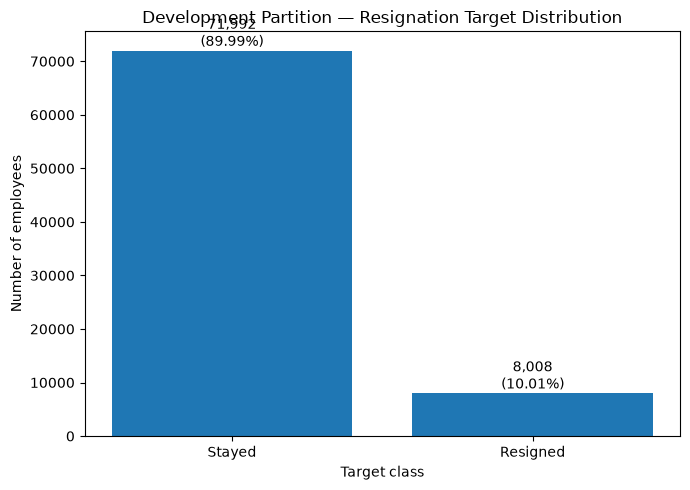

In [7]:
# ------------------------------------------------------------
# DEVELOPMENT TARGET DISTRIBUTION
# ------------------------------------------------------------

# Build a reproducible target-distribution table.
target_distribution = pd.DataFrame(
    {
        "Resigned": [False, True],
        "label": ["Stayed", "Resigned"],
        "count": [
            stayed_count,
            resigned_count,
        ],
    }
)

target_distribution["percentage"] = (
    target_distribution["count"]
    / len(development_df)
    * 100
)


display(target_distribution)


# Save the table.
target_distribution_file = (
    eda_results_folder
    / "target_distribution.csv"
)

target_distribution.to_csv(
    target_distribution_file,
    index=False,
)


# Create a clean development-only target distribution chart.
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    target_distribution["label"],
    target_distribution["count"],
)

ax.set_title("Development Partition — Resignation Target Distribution")
ax.set_xlabel("Target class")
ax.set_ylabel("Number of employees")


# Add count and percentage labels above each bar.
for bar, count, percentage in zip(
    bars,
    target_distribution["count"],
    target_distribution["percentage"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{count:,}\n({percentage:.2f}%)",
        ha="center",
        va="bottom",
    )


fig.tight_layout()

target_figure_file = (
    eda_results_folder
    / "figure_01_target_distribution.png"
)

fig.savefig(
    target_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## Numerical / Ordinal Feature Distributions

The next section examines the 13 approved numerical or ordinal predictors.

The purpose is to understand their ranges, central tendency, spread,
discreteness, and unusual observations before model-specific preprocessing.

Statistical extremes are treated as **diagnostic observations**, not automatic
deletion candidates. No row is removed in this notebook solely because it falls
outside an IQR rule.

In [8]:
# ------------------------------------------------------------
# NUMERICAL / ORDINAL DEVELOPMENT SUMMARY
# ------------------------------------------------------------

# Start with standard descriptive statistics.
numerical_summary = (
    development_df[numerical_features]
    .describe()
    .T
    .reset_index()
    .rename(columns={"index": "feature"})
)


# Add median and number of unique values for easier interpretation.
numerical_summary["median"] = [
    development_df[feature].median()
    for feature in numerical_features
]

numerical_summary["unique_values"] = [
    development_df[feature].nunique()
    for feature in numerical_features
]


# Reorder columns into a more evaluator-friendly layout.
numerical_summary = numerical_summary[
    [
        "feature",
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "median",
        "50%",
        "75%",
        "max",
        "unique_values",
    ]
]


display(numerical_summary)


# Save the development-only numerical summary.
numerical_summary_file = (
    eda_results_folder
    / "numerical_summary.csv"
)

numerical_summary.to_csv(
    numerical_summary_file,
    index=False,
)

,feature,count,mean,std,min,25%,median,50%,75%,max,unique_values
0,Age,80000.0,41.022287,11.236067,22.0,31.00,41.0,41.0,51.00,60.0,39
1,Years_At_Company,80000.0,4.477125,2.869687,0.0,2.00,4.0,4.0,7.00,10.0,11
2,Performance_Score,80000.0,2.996987,1.413587,1.0,2.00,3.0,3.0,4.00,5.0,5
3,Monthly_Salary,80000.0,6404.040625,1371.679937,3850.0,5250.00,6500.0,6500.0,7500.00,9000.0,28
4,Work_Hours_Per_Week,80000.0,44.945462,8.940655,30.0,37.00,45.0,45.0,53.00,60.0,31
5,Projects_Handled,80000.0,24.451050,14.452179,0.0,12.00,24.0,24.0,37.00,49.0,50
6,Overtime_Hours,80000.0,14.516737,8.662112,0.0,7.00,15.0,15.0,22.00,29.0,30
7,Sick_Days,80000.0,7.010962,4.330557,0.0,3.00,7.0,7.0,11.00,14.0,15
8,Remote_Work_Frequency,80000.0,50.037188,35.374208,0.0,25.00,50.0,50.0,75.00,100.0,5
9,Team_Size,80000.0,9.993412,5.502083,1.0,5.00,10.0,10.0,15.00,19.0,19


In [9]:
# ------------------------------------------------------------
# IQR-BASED OUTLIER DIAGNOSTIC
# ------------------------------------------------------------
#
# This is a review tool only.
# It does NOT remove, winsorize, clip, or otherwise alter records.

iqr_review_rows = []


for feature in numerical_features:

    # Calculate the standard 1.5 × IQR diagnostic fences.
    q1 = development_df[feature].quantile(0.25)
    q3 = development_df[feature].quantile(0.75)

    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    flagged_mask = (
        (development_df[feature] < lower_fence)
        | (development_df[feature] > upper_fence)
    )

    flagged_count = int(flagged_mask.sum())

    iqr_review_rows.append(
        {
            "feature": feature,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_fence": lower_fence,
            "upper_fence": upper_fence,
            "flagged_count": flagged_count,
            "flagged_percentage": (
                flagged_count / len(development_df) * 100
            ),
            "action_taken": "none",
        }
    )


numerical_iqr_review = pd.DataFrame(iqr_review_rows)


display(
    numerical_iqr_review.sort_values(
        "flagged_percentage",
        ascending=False,
    )
)


# Save the diagnostic.
numerical_iqr_review_file = (
    eda_results_folder
    / "numerical_iqr_review.csv"
)

numerical_iqr_review.to_csv(
    numerical_iqr_review_file,
    index=False,
)


print(
    "\nNo rows were removed or modified based on the IQR diagnostic."
)

,feature,q1,q3,iqr,lower_fence,upper_fence,flagged_count,flagged_percentage,action_taken
0,Age,31.00,51.00,20.00,1.00,81.00,0,0.0,none
1,Years_At_Company,2.00,7.00,5.00,-5.50,14.50,0,0.0,none
2,Performance_Score,2.00,4.00,2.00,-1.00,7.00,0,0.0,none
3,Monthly_Salary,5250.00,7500.00,2250.00,1875.00,10875.00,0,0.0,none
4,Work_Hours_Per_Week,37.00,53.00,16.00,13.00,77.00,0,0.0,none
5,Projects_Handled,12.00,37.00,25.00,-25.50,74.50,0,0.0,none
6,Overtime_Hours,7.00,22.00,15.00,-15.50,44.50,0,0.0,none
7,Sick_Days,3.00,11.00,8.00,-9.00,23.00,0,0.0,none
8,Remote_Work_Frequency,25.00,75.00,50.00,-50.00,150.00,0,0.0,none
9,Team_Size,5.00,15.00,10.00,-10.00,30.00,0,0.0,none



No rows were removed or modified based on the IQR diagnostic.


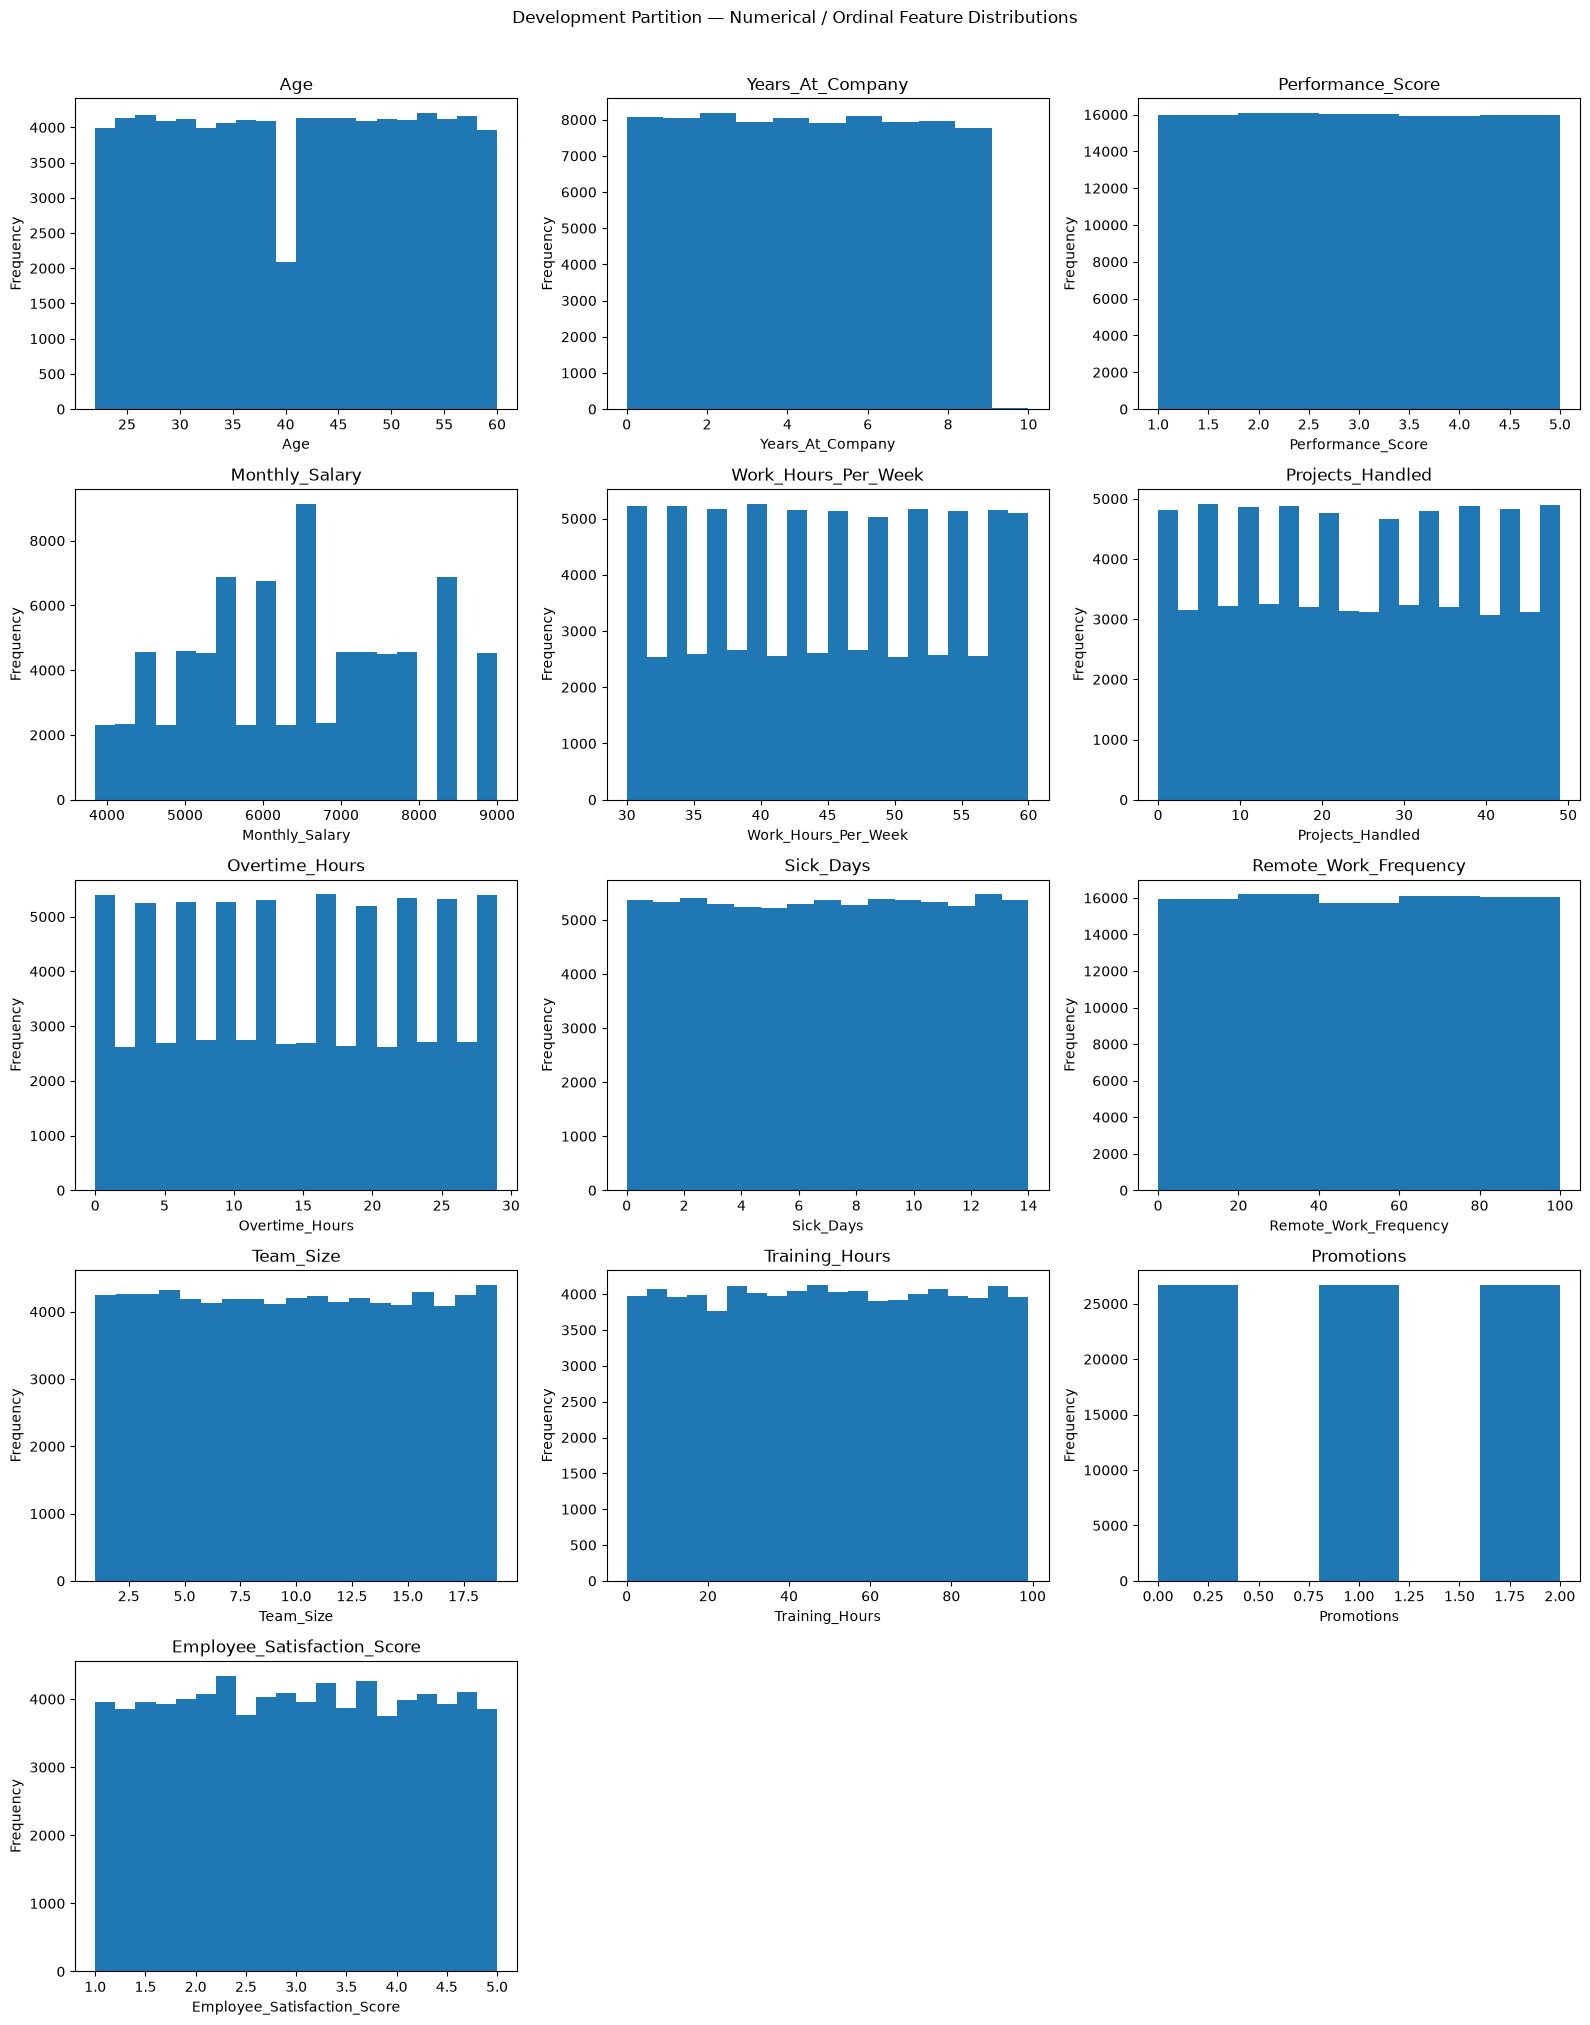

In [10]:
# ------------------------------------------------------------
# PLOT NUMERICAL / ORDINAL DISTRIBUTIONS
# ------------------------------------------------------------

# Use a fixed grid so all 13 approved numerical predictors are shown.
n_features = len(numerical_features)
n_columns = 3
n_rows = math.ceil(n_features / n_columns)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 4 * n_rows),
)

axes = np.array(axes).reshape(-1)


for index, feature in enumerate(numerical_features):

    ax = axes[index]

    series = development_df[feature].dropna()

    # Use fewer bins for low-cardinality discrete variables.
    unique_count = int(series.nunique())
    bins = max(5, min(20, unique_count))

    ax.hist(
        series,
        bins=bins,
    )

    ax.set_title(feature)
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")


# Hide unused subplot slots.
for index in range(n_features, len(axes)):
    axes[index].set_visible(False)


fig.suptitle(
    "Development Partition — Numerical / Ordinal Feature Distributions",
    y=1.01,
)

fig.tight_layout()

numeric_distribution_figure_file = (
    eda_results_folder
    / "figure_02_numerical_distributions.png"
)

fig.savefig(
    numeric_distribution_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## Numerical Features Compared With `Resigned`

This section compares every approved numerical or ordinal predictor between:

- employees who stayed (`Resigned=False`);
- employees who resigned (`Resigned=True`).

The comparisons are descriptive associations only. They do not establish that
a feature causes resignation.

A standardized mean difference is included as a scale-independent descriptive
effect-size measure. It is not a model-performance metric.

In [11]:
# ------------------------------------------------------------
# NUMERICAL FEATURES VS TARGET
# ------------------------------------------------------------

def standardized_mean_difference(
    stayed_values: pd.Series,
    resigned_values: pd.Series,
) -> float:
    """
    Calculate the standardized mean difference using the pooled
    sample standard deviation.

    Positive values mean the resigned group has the higher mean.
    """

    stayed_values = stayed_values.dropna().astype(float)
    resigned_values = resigned_values.dropna().astype(float)

    n_stayed = len(stayed_values)
    n_resigned = len(resigned_values)

    if n_stayed < 2 or n_resigned < 2:
        return np.nan

    stayed_variance = stayed_values.var(ddof=1)
    resigned_variance = resigned_values.var(ddof=1)

    pooled_variance = (
        (
            (n_stayed - 1) * stayed_variance
            + (n_resigned - 1) * resigned_variance
        )
        / (n_stayed + n_resigned - 2)
    )

    if pooled_variance <= 0:
        return np.nan

    pooled_std = math.sqrt(pooled_variance)

    return (
        resigned_values.mean()
        - stayed_values.mean()
    ) / pooled_std


numerical_target_rows = []


for feature in numerical_features:

    stayed_values = development_df.loc[
        development_df[target_column] == False,
        feature,
    ]

    resigned_values = development_df.loc[
        development_df[target_column] == True,
        feature,
    ]

    stayed_mean = stayed_values.mean()
    resigned_mean = resigned_values.mean()

    stayed_median = stayed_values.median()
    resigned_median = resigned_values.median()

    smd = standardized_mean_difference(
        stayed_values,
        resigned_values,
    )

    numerical_target_rows.append(
        {
            "feature": feature,
            "stayed_count": stayed_values.notna().sum(),
            "resigned_count": resigned_values.notna().sum(),
            "stayed_mean": stayed_mean,
            "resigned_mean": resigned_mean,
            "mean_difference_resigned_minus_stayed": (
                resigned_mean - stayed_mean
            ),
            "stayed_median": stayed_median,
            "resigned_median": resigned_median,
            "median_difference_resigned_minus_stayed": (
                resigned_median - stayed_median
            ),
            "standardized_mean_difference": smd,
            "absolute_standardized_mean_difference": abs(smd)
            if pd.notna(smd)
            else np.nan,
        }
    )


numerical_summary_by_target = pd.DataFrame(
    numerical_target_rows
).sort_values(
    "absolute_standardized_mean_difference",
    ascending=False,
)


display(numerical_summary_by_target)


# Save the numerical target-comparison table.
numerical_summary_by_target_file = (
    eda_results_folder
    / "numerical_summary_by_target.csv"
)

numerical_summary_by_target.to_csv(
    numerical_summary_by_target_file,
    index=False,
)

,feature,stayed_count,resigned_count,stayed_mean,resigned_mean,mean_difference_resigned_minus_stayed,stayed_median,resigned_median,median_difference_resigned_minus_stayed,standardized_mean_difference,absolute_standardized_mean_difference
8,Remote_Work_Frequency,71992,8008,49.921519,51.077048,1.155529,50.0,50.00,0.00,0.032667,0.032667
2,Performance_Score,71992,8008,2.999125,2.977772,-0.021353,3.0,3.00,0.00,-0.015105,0.015105
12,Employee_Satisfaction_Score,71992,8008,3.000473,2.985573,-0.014900,3.0,2.99,-0.01,-0.012959,0.012959
0,Age,71992,8008,41.015710,41.081419,0.065709,41.0,41.00,0.00,0.005848,0.005848
9,Team_Size,71992,8008,9.990930,10.015734,0.024805,10.0,10.00,0.00,0.004508,0.004508
10,Training_Hours,71992,8008,49.528059,49.641858,0.113799,49.0,50.00,1.00,0.003943,0.003943
5,Projects_Handled,71992,8008,24.456467,24.402348,-0.054120,24.0,24.00,0.00,-0.003745,0.003745
6,Overtime_Hours,71992,8008,14.514140,14.540085,0.025944,14.0,15.00,1.00,0.002995,0.002995
4,Work_Hours_Per_Week,71992,8008,44.943146,44.966284,0.023137,45.0,45.00,0.00,0.002588,0.002588
1,Years_At_Company,71992,8008,4.477539,4.473402,-0.004138,4.0,4.00,0.00,-0.001442,0.001442


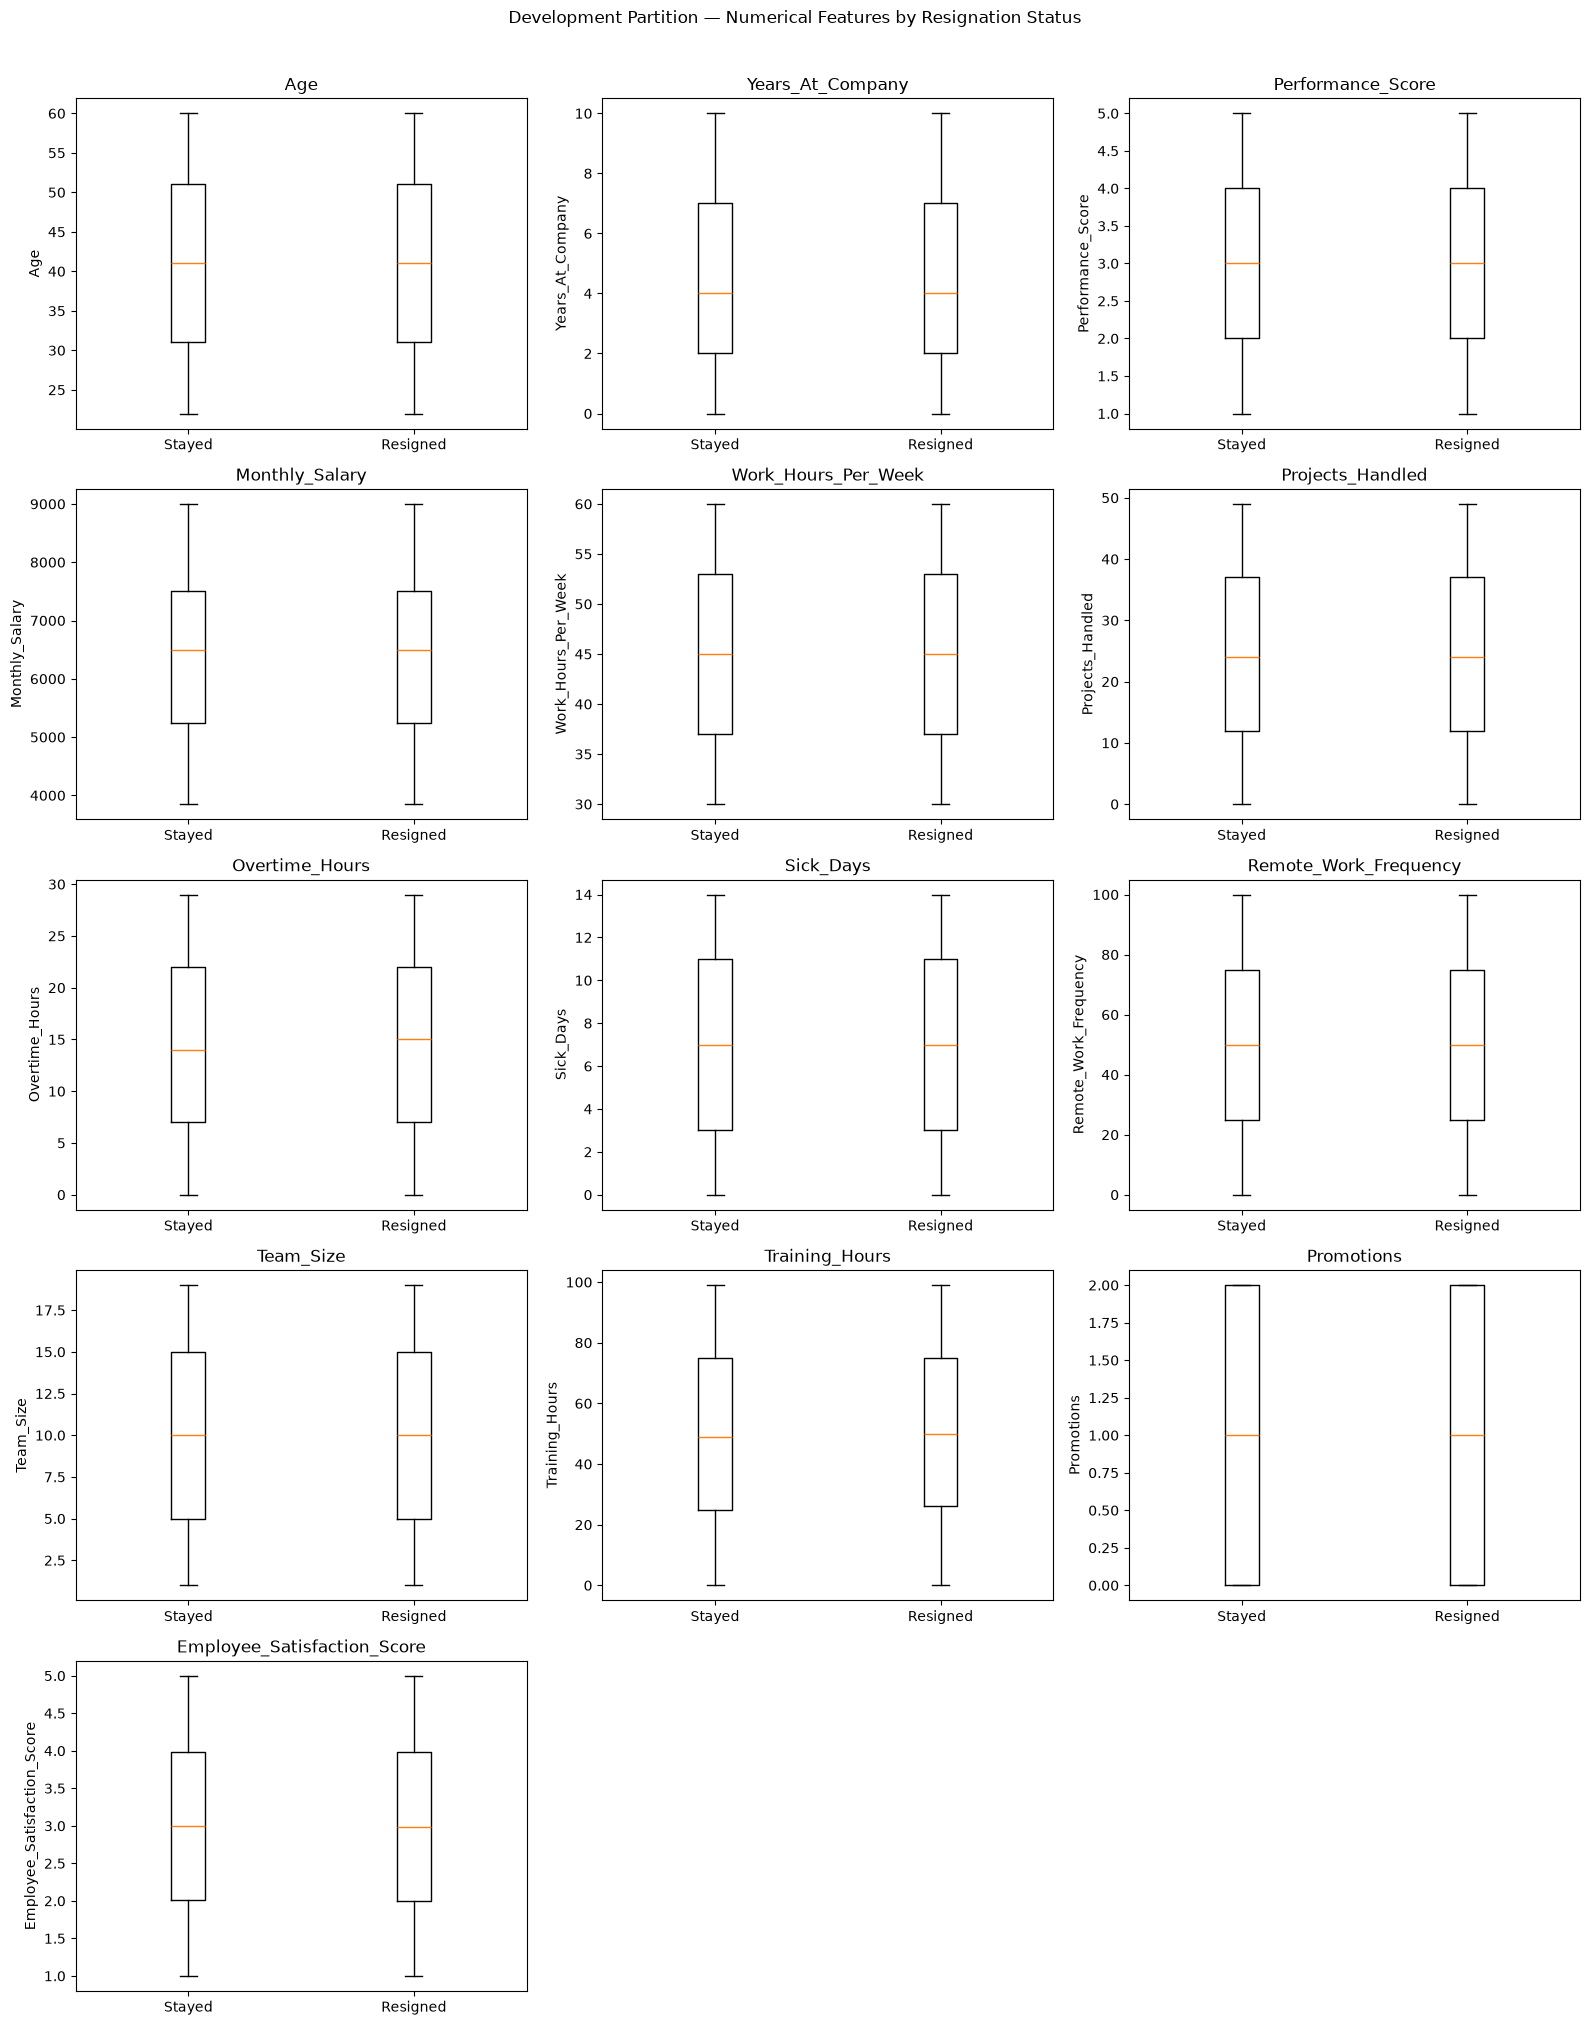

In [13]:
# ------------------------------------------------------------
# PLOT NUMERICAL FEATURES BY TARGET
# ------------------------------------------------------------

n_features = len(numerical_features)
n_columns = 3
n_rows = math.ceil(n_features / n_columns)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 4 * n_rows),
)

axes = np.array(axes).reshape(-1)


for index, feature in enumerate(numerical_features):

    ax = axes[index]

    stayed_values = development_df.loc[
        development_df[target_column] == False,
        feature,
    ].dropna()

    resigned_values = development_df.loc[
        development_df[target_column] == True,
        feature,
    ].dropna()

    # Outlier points are hidden here only to keep the plot readable.
    # No data points are removed from the dataset or calculations.
    ax.boxplot(
        [
            stayed_values,
            resigned_values,
        ],
        tick_labels=[
            "Stayed",
            "Resigned",
        ],
        showfliers=False,
    )

    ax.set_title(feature)
    ax.set_ylabel(feature)


# Hide unused subplot slots.
for index in range(n_features, len(axes)):
    axes[index].set_visible(False)


fig.suptitle(
    "Development Partition — Numerical Features by Resignation Status",
    y=1.01,
)

fig.tight_layout()

numeric_target_figure_file = (
    eda_results_folder
    / "figure_03_numerical_features_by_target.png"
)

fig.savefig(
    numeric_target_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## Categorical Feature Distributions

The approved categorical predictors are:

- `Department`
- `Gender`
- `Job_Title`
- `Education_Level`

This section first examines category sizes, then calculates resignation rates
within each category.

Category-level resignation rates must always be interpreted together with their
denominators. Small differences are descriptive and should not be presented as
causal effects.

In [14]:
# ------------------------------------------------------------
# CATEGORICAL FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

categorical_distribution_rows = []


for feature in categorical_features:

    category_counts = (
        development_df[feature]
        .value_counts(dropna=False)
    )

    for category, count in category_counts.items():

        categorical_distribution_rows.append(
            {
                "feature": feature,
                "category": category,
                "count": int(count),
                "percentage": (
                    count
                    / len(development_df)
                    * 100
                ),
            }
        )


categorical_distribution = pd.DataFrame(
    categorical_distribution_rows
)


display(categorical_distribution)


# Save the distribution table.
categorical_distribution_file = (
    eda_results_folder
    / "categorical_distribution.csv"
)

categorical_distribution.to_csv(
    categorical_distribution_file,
    index=False,
)

,feature,category,count,percentage
0,Department,Operations,9037,11.29625
1,Department,Marketing,8969,11.21125
2,Department,Sales,8936,11.17000
3,Department,Customer Support,8927,11.15875
4,Department,Finance,8895,11.11875
5,Department,IT,8892,11.11500
6,Department,Legal,8855,11.06875
7,Department,HR,8749,10.93625
8,Department,Engineering,8740,10.92500
9,Gender,Male,38537,48.17125


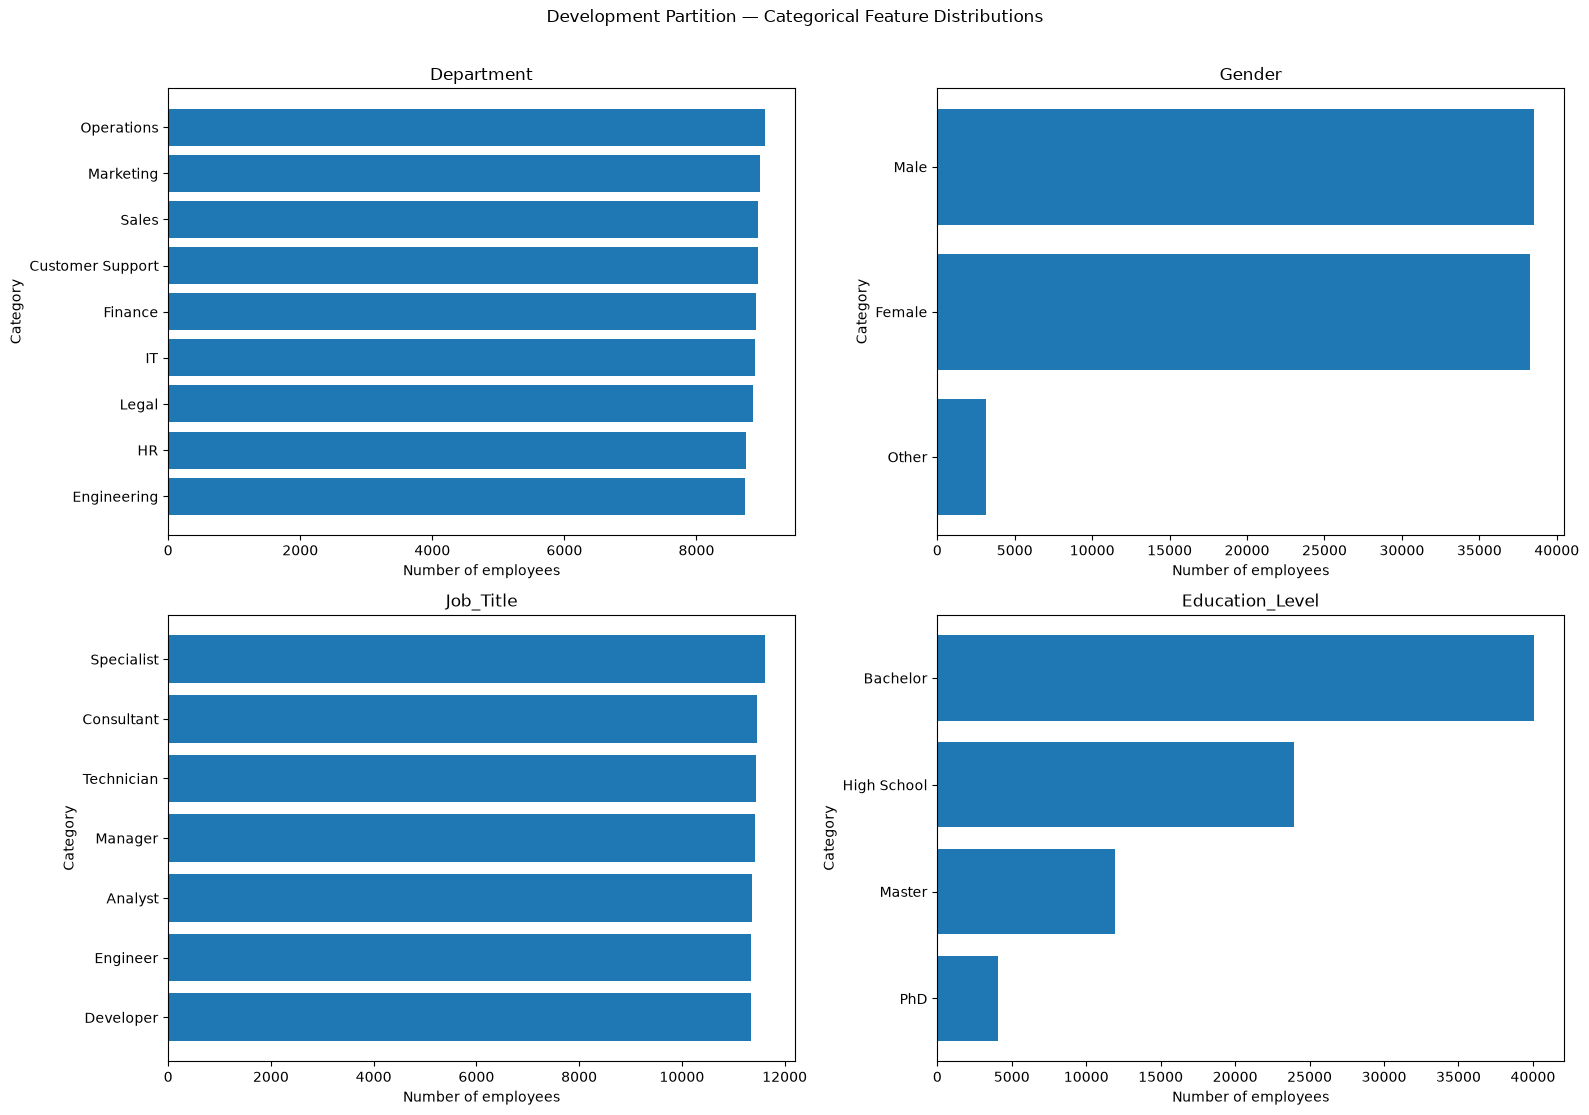

In [15]:
# ------------------------------------------------------------
# PLOT CATEGORICAL FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11),
)

axes = axes.reshape(-1)


for index, feature in enumerate(categorical_features):

    ax = axes[index]

    counts = (
        development_df[feature]
        .value_counts()
        .sort_values(ascending=True)
    )

    ax.barh(
        counts.index.astype(str),
        counts.values,
    )

    ax.set_title(feature)
    ax.set_xlabel("Number of employees")
    ax.set_ylabel("Category")


fig.suptitle(
    "Development Partition — Categorical Feature Distributions",
    y=1.01,
)

fig.tight_layout()

categorical_distribution_figure_file = (
    eda_results_folder
    / "figure_04_categorical_distributions.png"
)

fig.savefig(
    categorical_distribution_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [16]:
# ------------------------------------------------------------
# CATEGORICAL FEATURES VS TARGET
# ------------------------------------------------------------

categorical_rate_rows = []


for feature in categorical_features:

    grouped = (
        development_df
        .groupby(
            feature,
            dropna=False,
        )[target_column]
        .agg(
            total_records="size",
            resigned_count="sum",
        )
        .reset_index()
    )

    grouped["stayed_count"] = (
        grouped["total_records"]
        - grouped["resigned_count"]
    )

    grouped["resignation_rate"] = (
        grouped["resigned_count"]
        / grouped["total_records"]
    )

    grouped["resignation_rate_percentage"] = (
        grouped["resignation_rate"]
        * 100
    )

    grouped["difference_from_overall_rate_percentage_points"] = (
        (
            grouped["resignation_rate"]
            - development_positive_rate
        )
        * 100
    )

    grouped.insert(
        0,
        "feature",
        feature,
    )

    grouped = grouped.rename(
        columns={
            feature: "category",
        }
    )

    categorical_rate_rows.append(grouped)


categorical_resignation_rates = pd.concat(
    categorical_rate_rows,
    ignore_index=True,
)


display(
    categorical_resignation_rates.sort_values(
        [
            "feature",
            "resignation_rate",
        ],
        ascending=[
            True,
            False,
        ],
    )
)


# Save category-level target rates.
categorical_resignation_rates_file = (
    eda_results_folder
    / "categorical_resignation_rates.csv"
)

categorical_resignation_rates.to_csv(
    categorical_resignation_rates_file,
    index=False,
)

,feature,category,total_records,resigned_count,stayed_count,resignation_rate,resignation_rate_percentage,difference_from_overall_rate_percentage_points
2,Department,Finance,8895,943,7952,0.106015,10.601461,0.591461
5,Department,Legal,8855,923,7932,0.104235,10.423490,0.413490
3,Department,HR,8749,885,7864,0.101154,10.115442,0.105442
6,Department,Marketing,8969,907,8062,0.101126,10.112610,0.102610
7,Department,Operations,9037,907,8130,0.100365,10.036517,0.026517
8,Department,Sales,8936,895,8041,0.100157,10.015667,0.005667
0,Department,Customer Support,8927,875,8052,0.098017,9.801725,-0.208275
1,Department,Engineering,8740,841,7899,0.096224,9.622426,-0.387574
4,Department,IT,8892,832,8060,0.093567,9.356725,-0.653275
20,Education_Level,High School,23942,2407,21535,0.100535,10.053463,0.043463


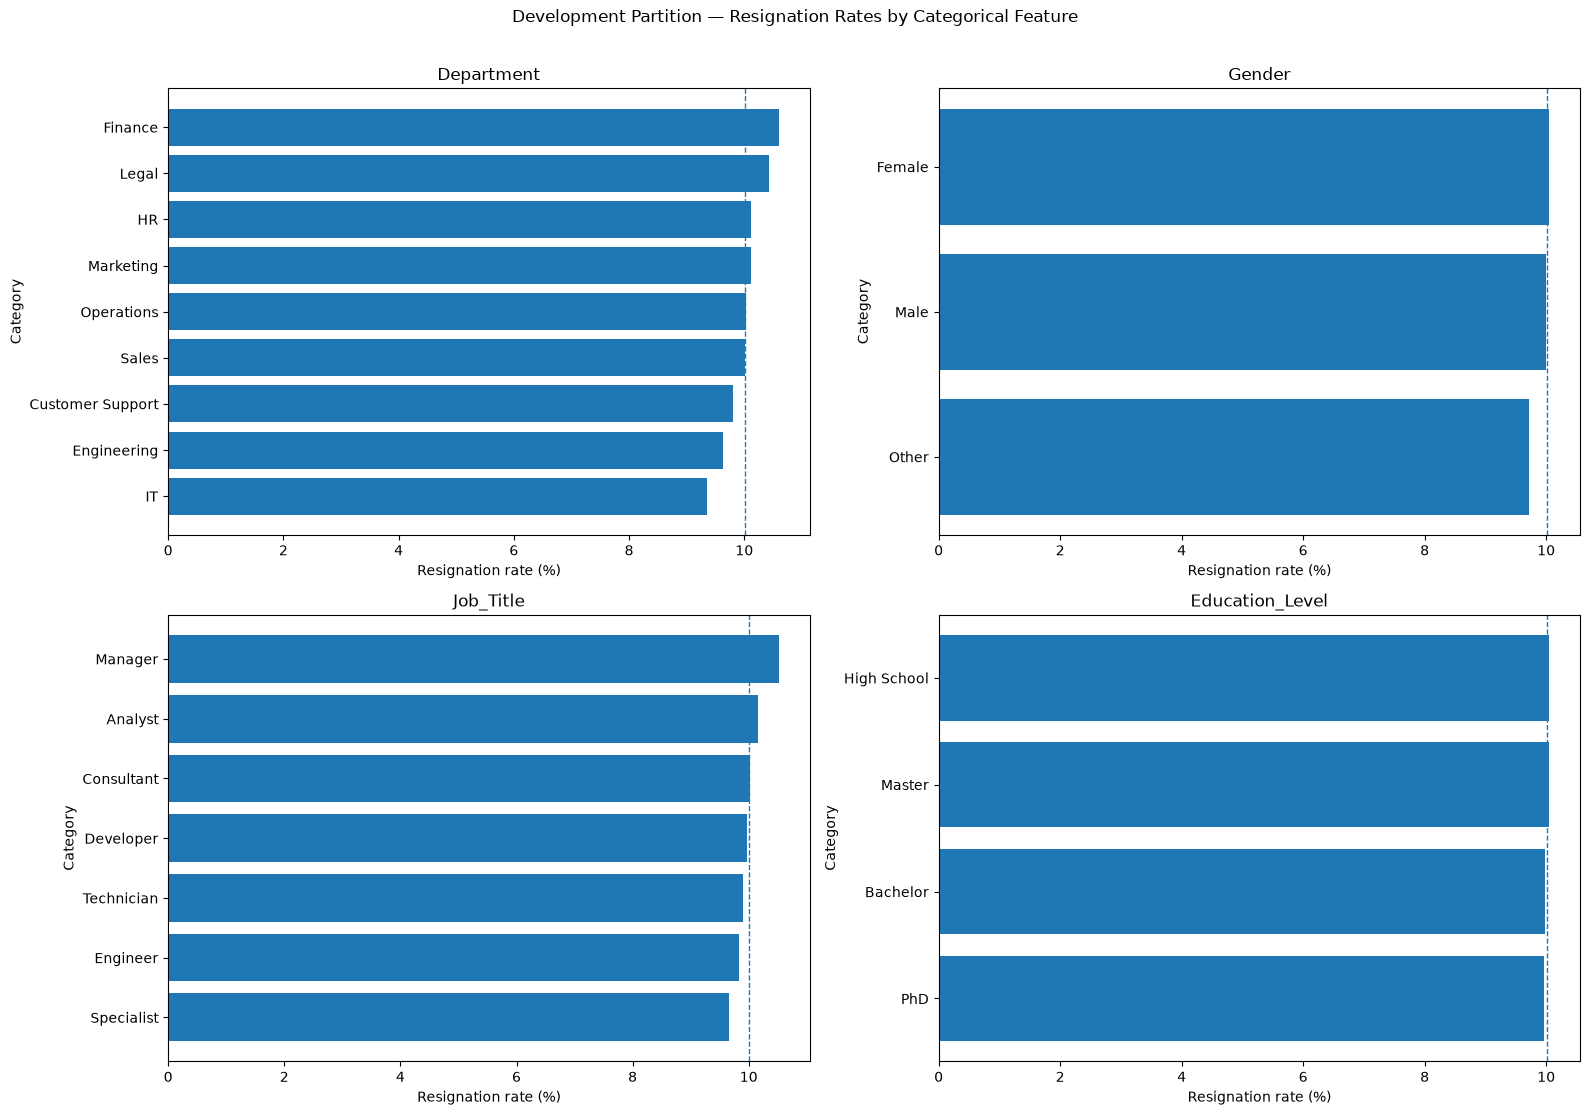

In [17]:
# ------------------------------------------------------------
# PLOT CATEGORICAL RESIGNATION RATES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(16, 11),
)

axes = axes.reshape(-1)


for index, feature in enumerate(categorical_features):

    ax = axes[index]

    feature_rates = (
        categorical_resignation_rates.loc[
            categorical_resignation_rates["feature"] == feature
        ]
        .sort_values(
            "resignation_rate_percentage",
            ascending=True,
        )
    )

    ax.barh(
        feature_rates["category"].astype(str),
        feature_rates["resignation_rate_percentage"],
    )

    # Show the overall development positive rate as a reference line.
    ax.axvline(
        development_positive_rate * 100,
        linestyle="--",
        linewidth=1,
    )

    ax.set_title(feature)
    ax.set_xlabel("Resignation rate (%)")
    ax.set_ylabel("Category")


fig.suptitle(
    "Development Partition — Resignation Rates by Categorical Feature",
    y=1.01,
)

fig.tight_layout()

categorical_target_figure_file = (
    eda_results_folder
    / "figure_05_categorical_resignation_rates.png"
)

fig.savefig(
    categorical_target_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## Correlation and Redundancy Analysis

Correlation is used here only as a descriptive measure of association.

It does not establish causality, and ordinary Pearson correlation does not
capture every possible nonlinear or categorical relationship.

The project audit has already identified important construction-like
regularities, especially the deterministic relationship between
`Monthly_Salary`, `Job_Title`, and `Performance_Score`. This section verifies
the relevant development-only structure without changing the frozen feature
contract.

,feature,target_correlation,absolute_target_correlation
8,Remote_Work_Frequency,0.009804,0.009804
2,Performance_Score,-0.004534,0.004534
12,Employee_Satisfaction_Score,-0.003890,0.003890
0,Age,0.001755,0.001755
9,Team_Size,0.001353,0.001353
10,Training_Hours,0.001183,0.001183
5,Projects_Handled,-0.001124,0.001124
6,Overtime_Hours,0.000899,0.000899
4,Work_Hours_Per_Week,0.000777,0.000777
1,Years_At_Company,-0.000433,0.000433


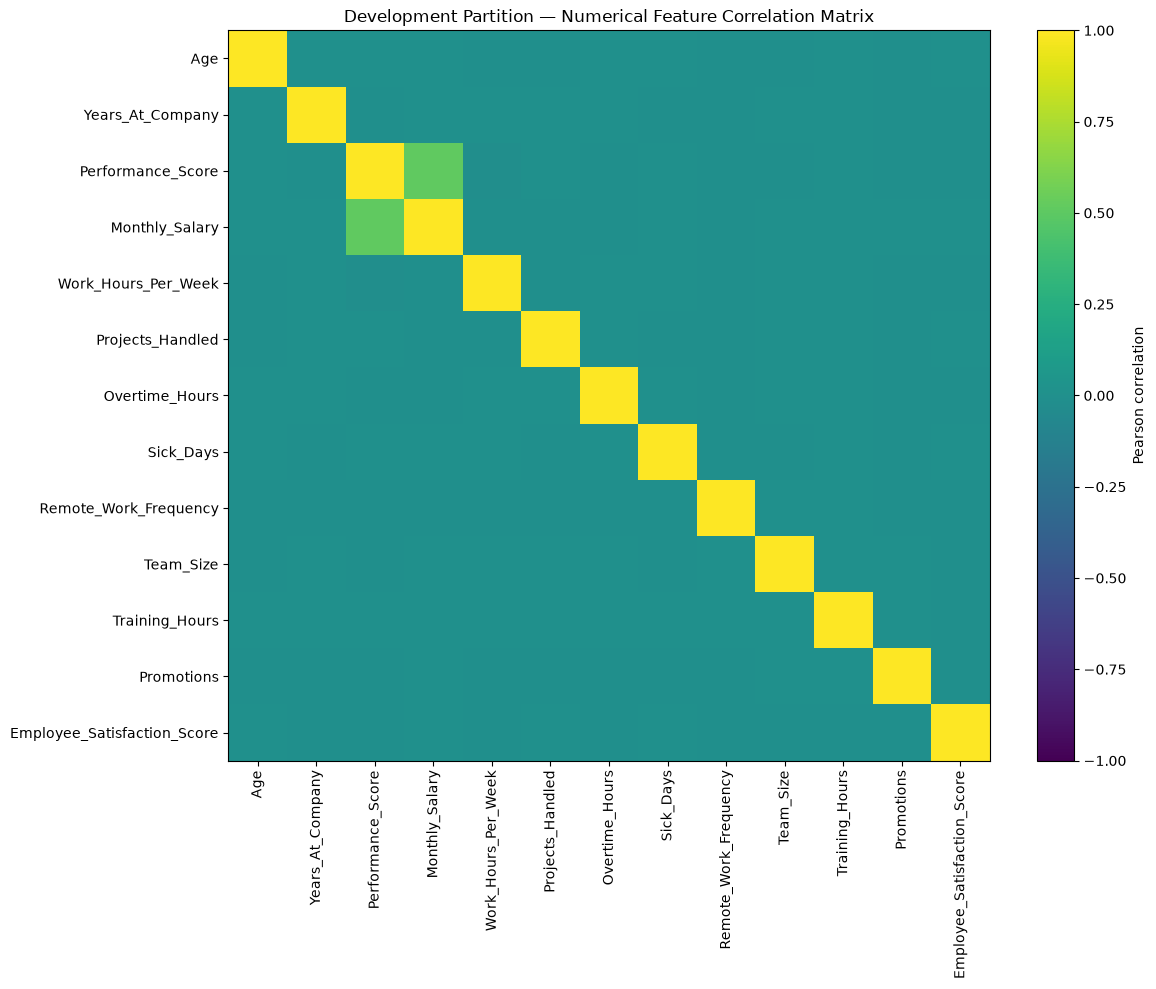

In [18]:
# ------------------------------------------------------------
# NUMERICAL CORRELATION ANALYSIS
# ------------------------------------------------------------

# Calculate Pearson correlations among approved numerical predictors.
correlation_matrix = (
    development_df[numerical_features]
    .corr(method="pearson")
)


# Calculate each numerical feature's Pearson correlation
# with the binary target for descriptive reference.
target_as_integer = (
    development_df[target_column]
    .astype(int)
)

numerical_target_correlations = (
    development_df[numerical_features]
    .corrwith(target_as_integer)
    .rename("target_correlation")
    .reset_index()
    .rename(columns={"index": "feature"})
)

numerical_target_correlations[
    "absolute_target_correlation"
] = (
    numerical_target_correlations[
        "target_correlation"
    ].abs()
)

numerical_target_correlations = (
    numerical_target_correlations
    .sort_values(
        "absolute_target_correlation",
        ascending=False,
    )
)


display(numerical_target_correlations)


# Save the correlation tables.
correlation_matrix_file = (
    eda_results_folder
    / "correlation_matrix.csv"
)

correlation_matrix.to_csv(
    correlation_matrix_file,
    index=True,
)


numerical_target_correlations_file = (
    eda_results_folder
    / "numerical_target_correlations.csv"
)

numerical_target_correlations.to_csv(
    numerical_target_correlations_file,
    index=False,
)


# Create a correlation heatmap using matplotlib only.
fig, ax = plt.subplots(
    figsize=(12, 10)
)

heatmap = ax.imshow(
    correlation_matrix.values,
    aspect="auto",
    vmin=-1,
    vmax=1,
)

ax.set_xticks(
    range(len(numerical_features))
)

ax.set_xticklabels(
    numerical_features,
    rotation=90,
)

ax.set_yticks(
    range(len(numerical_features))
)

ax.set_yticklabels(
    numerical_features,
)

ax.set_title(
    "Development Partition — Numerical Feature Correlation Matrix"
)

fig.colorbar(
    heatmap,
    ax=ax,
    label="Pearson correlation",
)

fig.tight_layout()

correlation_figure_file = (
    eda_results_folder
    / "figure_06_correlation_heatmap.png"
)

fig.savefig(
    correlation_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

In [19]:
# ------------------------------------------------------------
# VERIFY KNOWN MONTHLY_SALARY STRUCTURE IN DEVELOPMENT DATA
# ------------------------------------------------------------

# The mechanical audit found that Job_Title + Performance_Score
# maps deterministically to Monthly_Salary.
#
# Re-check that relationship in the development partition only.
salary_structure_summary = (
    development_df
    .groupby(
        [
            "Job_Title",
            "Performance_Score",
        ],
        dropna=False,
    )
    .agg(
        record_count=(
            "Monthly_Salary",
            "size",
        ),
        unique_salary_count=(
            "Monthly_Salary",
            "nunique",
        ),
        minimum_salary=(
            "Monthly_Salary",
            "min",
        ),
        maximum_salary=(
            "Monthly_Salary",
            "max",
        ),
    )
    .reset_index()
)


salary_deterministic_in_development = bool(
    (
        salary_structure_summary[
            "unique_salary_count"
        ]
        == 1
    ).all()
)


display(salary_structure_summary)


print(
    "\nMonthly_Salary is deterministic within each observed "
    "Job_Title + Performance_Score combination:",
    salary_deterministic_in_development,
)


# Save the development-only salary structure.
salary_structure_summary_file = (
    eda_results_folder
    / "salary_structure_summary.csv"
)

salary_structure_summary.to_csv(
    salary_structure_summary_file,
    index=False,
)

,Job_Title,Performance_Score,record_count,unique_salary_count,minimum_salary,maximum_salary
0,Analyst,1,2264,1,4400.0,4400.0
1,Analyst,2,2318,1,4800.0,4800.0
2,Analyst,3,2303,1,5200.0,5200.0
3,Analyst,4,2261,1,5600.0,5600.0
4,Analyst,5,2226,1,6000.0,6000.0
5,Consultant,1,2254,1,6050.0,6050.0
6,Consultant,2,2290,1,6600.0,6600.0
7,Consultant,3,2293,1,7150.0,7150.0
8,Consultant,4,2258,1,7700.0,7700.0
9,Consultant,5,2359,1,8250.0,8250.0



Monthly_Salary is deterministic within each observed Job_Title + Performance_Score combination: True


## Sensitive-Attribute Descriptive Analysis

`Gender` and `Age` are approved primary predictors and are also sensitive/audit
attributes.

This section provides descriptive development-only context for later fairness
analysis. It does **not** conclude that a model is fair or unfair.

The frozen project age bands are:

- 22–29
- 30–39
- 40–49
- 50–60

Formal subgroup model evaluation is performed later in
`13_fairness_analysis.ipynb`.

In [20]:
# ------------------------------------------------------------
# SENSITIVE-ATTRIBUTE DESCRIPTIVE SUMMARY
# ------------------------------------------------------------

# Construct age bands directly from the frozen feature contract.
age_band_definitions = feature_contract["age_bands"]

age_band_labels = [
    item["label"]
    for item in age_band_definitions
]

age_band_bins = [
    age_band_definitions[0]["minimum"] - 1
] + [
    item["maximum"]
    for item in age_band_definitions
]


development_df["age_band"] = pd.cut(
    development_df["Age"],
    bins=age_band_bins,
    labels=age_band_labels,
    include_lowest=True,
    right=True,
)


# Every development record must fall into one frozen age band.
if development_df["age_band"].isna().any():
    raise ValueError(
        "At least one development Age is outside the frozen age-band contract."
    )


# Gender summary.
gender_summary = (
    development_df
    .groupby(
        "Gender",
        dropna=False,
    )[target_column]
    .agg(
        total_records="size",
        resigned_count="sum",
    )
    .reset_index()
    .rename(
        columns={
            "Gender": "group",
        }
    )
)

gender_summary.insert(
    0,
    "sensitive_attribute",
    "Gender",
)


# Age-band summary.
age_band_summary = (
    development_df
    .groupby(
        "age_band",
        observed=False,
    )[target_column]
    .agg(
        total_records="size",
        resigned_count="sum",
    )
    .reset_index()
    .rename(
        columns={
            "age_band": "group",
        }
    )
)

age_band_summary.insert(
    0,
    "sensitive_attribute",
    "Age_Band",
)


# Combine the two descriptive summaries.
sensitive_attribute_summary = pd.concat(
    [
        gender_summary,
        age_band_summary,
    ],
    ignore_index=True,
)

sensitive_attribute_summary["stayed_count"] = (
    sensitive_attribute_summary["total_records"]
    - sensitive_attribute_summary["resigned_count"]
)

sensitive_attribute_summary["resignation_rate"] = (
    sensitive_attribute_summary["resigned_count"]
    / sensitive_attribute_summary["total_records"]
)

sensitive_attribute_summary["resignation_rate_percentage"] = (
    sensitive_attribute_summary["resignation_rate"]
    * 100
)


display(sensitive_attribute_summary)


# Save the descriptive subgroup table.
sensitive_attribute_summary_file = (
    eda_results_folder
    / "sensitive_attribute_summary.csv"
)

sensitive_attribute_summary.to_csv(
    sensitive_attribute_summary_file,
    index=False,
)

,sensitive_attribute,group,total_records,resigned_count,stayed_count,resignation_rate,resignation_rate_percentage
0,Gender,Female,38303,3851,34452,0.100540,10.054043
1,Gender,Male,38537,3850,34687,0.099904,9.990399
2,Gender,Other,3160,307,2853,0.097152,9.715190
3,Age_Band,22-29,16391,1653,14738,0.100848,10.084803
4,Age_Band,30-39,20368,2011,18357,0.098733,9.873331
5,Age_Band,40-49,20605,2059,18546,0.099927,9.992720
6,Age_Band,50-60,22636,2285,20351,0.100945,10.094540


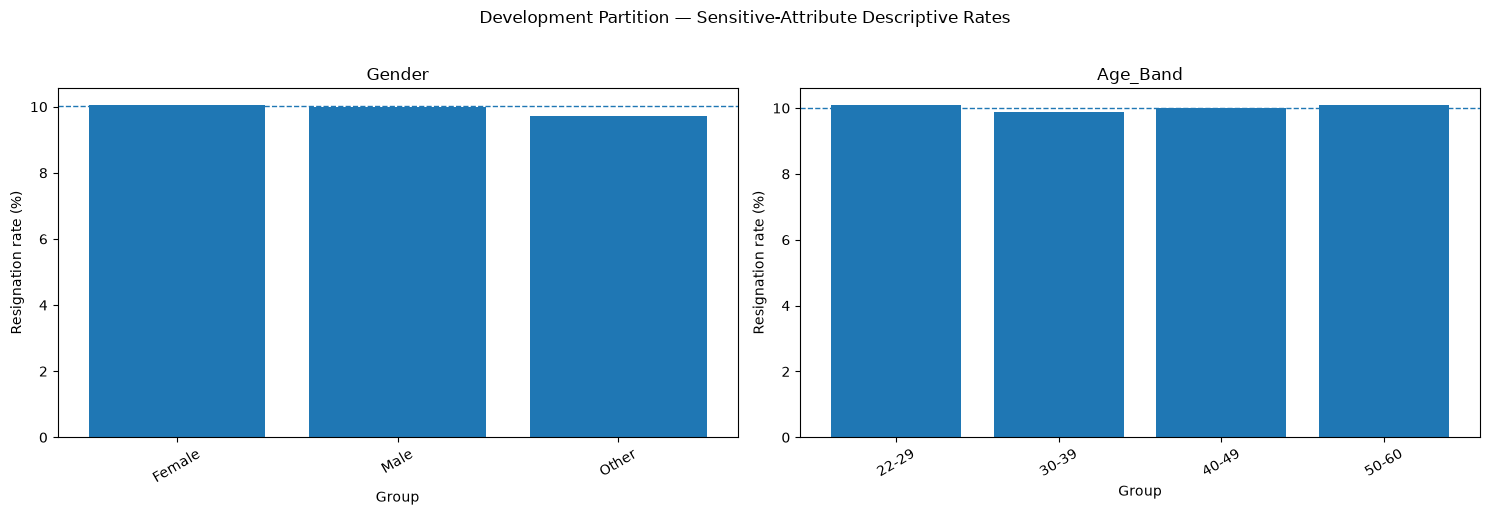

In [21]:
# ------------------------------------------------------------
# PLOT SENSITIVE-ATTRIBUTE RESIGNATION RATES
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(15, 5),
)


for ax, attribute in zip(
    axes,
    [
        "Gender",
        "Age_Band",
    ],
):

    attribute_data = (
        sensitive_attribute_summary.loc[
            sensitive_attribute_summary[
                "sensitive_attribute"
            ]
            == attribute
        ]
        .copy()
    )

    ax.bar(
        attribute_data["group"].astype(str),
        attribute_data["resignation_rate_percentage"],
    )

    ax.axhline(
        development_positive_rate * 100,
        linestyle="--",
        linewidth=1,
    )

    ax.set_title(attribute)
    ax.set_xlabel("Group")
    ax.set_ylabel("Resignation rate (%)")

    ax.tick_params(
        axis="x",
        rotation=30,
    )


fig.suptitle(
    "Development Partition — Sensitive-Attribute Descriptive Rates",
    y=1.02,
)

fig.tight_layout()

sensitive_figure_file = (
    eda_results_folder
    / "figure_07_sensitive_attribute_resignation_rates.png"
)

fig.savefig(
    sensitive_figure_file,
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

## Preprocessing and Modelling Implications

EDA does not create a single processed dataset for all six models.

The six headline algorithms have different representation requirements, so
learned transformations will later be fitted separately inside each model's
training folds.

This section records shared conclusions that follow from the audit, frozen
feature contract, and development-only EDA without implementing the model
pipelines themselves.

In [22]:
# ------------------------------------------------------------
# DOCUMENT SHARED PREPROCESSING / MODELLING IMPLICATIONS
# ------------------------------------------------------------

# Record decisions and constraints without fitting any transformation.
preprocessing_implications = pd.DataFrame(
    [
        {
            "topic": "Missing values",
            "eda_observation": (
                f"{total_development_missing} missing values were found "
                "across the approved predictors and target."
            ),
            "shared_implication": (
                "No dataset-wide imputation is performed in EDA. "
                "Any defensive missing-value handling later remains "
                "model-specific and training-fold-local."
            ),
        },
        {
            "topic": "Categorical predictors",
            "eda_observation": (
                "Four categorical predictors are frozen in the feature contract."
            ),
            "shared_implication": (
                "Do not create one universal encoded matrix. "
                "Categorical representation is model-specific."
            ),
        },
        {
            "topic": "Numerical scaling",
            "eda_observation": (
                "Numerical predictors have different ranges and cardinalities."
            ),
            "shared_implication": (
                "Scaling is applied only for models that need it and must be "
                "fitted on the active training fold only."
            ),
        },
        {
            "topic": "Statistical outliers",
            "eda_observation": (
                "IQR diagnostics were calculated for review."
            ),
            "shared_implication": (
                "No row is removed solely because it is statistically extreme. "
                "Any later treatment requires explicit justification."
            ),
        },
        {
            "topic": "Employee_ID",
            "eda_observation": (
                "Employee_ID is retained only for record traceability."
            ),
            "shared_implication": (
                "Employee_ID must never enter a predictor matrix."
            ),
        },
        {
            "topic": "Hire_Date",
            "eda_observation": (
                "The prior audit found strong redundancy with Years_At_Company "
                "and construction-like regularity."
            ),
            "shared_implication": (
                "Raw Hire_Date remains excluded from primary modelling."
            ),
        },
        {
            "topic": "Monthly_Salary",
            "eda_observation": (
                "Development-only analysis verifies the known deterministic "
                "Job_Title + Performance_Score salary structure."
            ),
            "shared_implication": (
                "Monthly_Salary remains in the frozen primary feature set. "
                "A later no-salary sensitivity analysis tests robustness."
            ),
        },
        {
            "topic": "Target imbalance",
            "eda_observation": (
                f"Development resignation prevalence is "
                f"{development_positive_rate * 100:.2f}%."
            ),
            "shared_implication": (
                "Do not judge models by accuracy alone. "
                "PR-AUC / Average Precision is the primary comparison metric."
            ),
        },
        {
            "topic": "Remote_Work_Frequency",
            "eda_observation": (
                "The feature is discrete and represented numerically/ordinally."
            ),
            "shared_implication": (
                "Do not invent an undocumented observation period or semantics. "
                "Keep the frozen primary representation unless a shared decision changes it."
            ),
        },
    ]
)


display(preprocessing_implications)


# Save the documented implications.
preprocessing_implications_file = (
    eda_results_folder
    / "preprocessing_implications.csv"
)

preprocessing_implications.to_csv(
    preprocessing_implications_file,
    index=False,
)

,topic,eda_observation,shared_implication
0,Missing values,0 missing values were found across the approve...,No dataset-wide imputation is performed in EDA...
1,Categorical predictors,Four categorical predictors are frozen in the ...,Do not create one universal encoded matrix. Ca...
2,Numerical scaling,Numerical predictors have different ranges and...,Scaling is applied only for models that need i...
3,Statistical outliers,IQR diagnostics were calculated for review.,No row is removed solely because it is statist...
4,Employee_ID,Employee_ID is retained only for record tracea...,Employee_ID must never enter a predictor matrix.
5,Hire_Date,The prior audit found strong redundancy with Y...,Raw Hire_Date remains excluded from primary mo...
6,Monthly_Salary,Development-only analysis verifies the known d...,Monthly_Salary remains in the frozen primary f...
7,Target imbalance,Development resignation prevalence is 10.01%.,Do not judge models by accuracy alone. PR-AUC ...
8,Remote_Work_Frequency,The feature is discrete and represented numeri...,Do not invent an undocumented observation peri...


## EDA Findings and Modelling Implications

The following cell produces an objective evidence summary directly from the
development-only calculations above.

The reported values are descriptive univariate associations and structural
observations. They are **not** causal conclusions and are **not** substitutes
for cross-validated model evaluation.

In [23]:
# ------------------------------------------------------------
# BUILD OBJECTIVE EDA KEY FINDINGS
# ------------------------------------------------------------

# Strongest numerical feature by absolute standardized mean difference.
top_numerical_smd_row = (
    numerical_summary_by_target
    .dropna(
        subset=[
            "absolute_standardized_mean_difference"
        ]
    )
    .iloc[0]
)


# Strongest numerical linear target association.
top_target_correlation_row = (
    numerical_target_correlations
    .dropna(
        subset=[
            "absolute_target_correlation"
        ]
    )
    .iloc[0]
)


# Calculate the category resignation-rate spread for each
# categorical predictor.
categorical_rate_spreads = (
    categorical_resignation_rates
    .groupby("feature")[
        "resignation_rate"
    ]
    .agg(
        lambda values:
        values.max() - values.min()
    )
    .sort_values(
        ascending=False
    )
)


largest_categorical_spread_feature = (
    categorical_rate_spreads.index[0]
)

largest_categorical_spread = float(
    categorical_rate_spreads.iloc[0]
)


# Record the observed discrete values for Remote_Work_Frequency
# without inventing their undocumented real-world observation period.
remote_work_values = sorted(
    development_df[
        "Remote_Work_Frequency"
    ]
    .dropna()
    .unique()
    .tolist()
)


# Create a machine-readable key-findings table.
eda_key_findings = pd.DataFrame(
    [
        {
            "finding": "development_resignation_rate",
            "feature": target_column,
            "value": development_positive_rate,
            "unit": "proportion",
        },
        {
            "finding": "largest_absolute_numerical_smd",
            "feature": top_numerical_smd_row["feature"],
            "value": top_numerical_smd_row[
                "absolute_standardized_mean_difference"
            ],
            "unit": "standardized_mean_difference",
        },
        {
            "finding": "largest_absolute_numerical_target_correlation",
            "feature": top_target_correlation_row["feature"],
            "value": top_target_correlation_row[
                "absolute_target_correlation"
            ],
            "unit": "absolute_pearson_correlation",
        },
        {
            "finding": "largest_categorical_resignation_rate_spread",
            "feature": largest_categorical_spread_feature,
            "value": largest_categorical_spread * 100,
            "unit": "percentage_points",
        },
        {
            "finding": "salary_deterministic_within_job_title_and_performance_score",
            "feature": "Monthly_Salary",
            "value": salary_deterministic_in_development,
            "unit": "boolean",
        },
    ]
)


display(eda_key_findings)


# Save the key-findings table.
eda_key_findings_file = (
    eda_results_folder
    / "eda_key_findings.csv"
)

eda_key_findings.to_csv(
    eda_key_findings_file,
    index=False,
)


# Print a concise evidence summary for human review.
print("EDA EVIDENCE SUMMARY")
print("-" * 60)

print(
    f"Development resignation prevalence: "
    f"{development_positive_rate * 100:.2f}%"
)

print(
    "Largest absolute numerical standardized mean difference: "
    f"{top_numerical_smd_row['feature']} "
    f"({top_numerical_smd_row['absolute_standardized_mean_difference']:.4f})"
)

print(
    "Largest absolute numerical Pearson target correlation: "
    f"{top_target_correlation_row['feature']} "
    f"({top_target_correlation_row['absolute_target_correlation']:.4f})"
)

print(
    "Largest categorical resignation-rate spread: "
    f"{largest_categorical_spread_feature} "
    f"({largest_categorical_spread * 100:.4f} percentage points)"
)

print(
    "Monthly_Salary deterministic within observed "
    "Job_Title + Performance_Score combinations:",
    salary_deterministic_in_development,
)

print(
    "Observed Remote_Work_Frequency values:",
    remote_work_values,
)

print(
    "\nInterpret these as development-only descriptive evidence, "
    "not causal effects or model-performance results."
)

,finding,feature,value,unit
0,development_resignation_rate,Resigned,0.1001,proportion
1,largest_absolute_numerical_smd,Remote_Work_Frequency,0.032667,standardized_mean_difference
2,largest_absolute_numerical_target_correlation,Remote_Work_Frequency,0.009804,absolute_pearson_correlation
3,largest_categorical_resignation_rate_spread,Department,1.244736,percentage_points
4,salary_deterministic_within_job_title_and_perf...,Monthly_Salary,True,boolean


EDA EVIDENCE SUMMARY
------------------------------------------------------------
Development resignation prevalence: 10.01%
Largest absolute numerical standardized mean difference: Remote_Work_Frequency (0.0327)
Largest absolute numerical Pearson target correlation: Remote_Work_Frequency (0.0098)
Largest categorical resignation-rate spread: Department (1.2447 percentage points)
Monthly_Salary deterministic within observed Job_Title + Performance_Score combinations: True
Observed Remote_Work_Frequency values: [0, 25, 50, 75, 100]

Interpret these as development-only descriptive evidence, not causal effects or model-performance results.


In [24]:
# ------------------------------------------------------------
# CREATE AN EDA OUTPUT MANIFEST
# ------------------------------------------------------------

# List the output files that this notebook is expected to create.
expected_eda_outputs = [
    development_dataset_summary_file,
    target_distribution_file,
    numerical_summary_file,
    numerical_iqr_review_file,
    numerical_summary_by_target_file,
    categorical_distribution_file,
    categorical_resignation_rates_file,
    correlation_matrix_file,
    numerical_target_correlations_file,
    salary_structure_summary_file,
    sensitive_attribute_summary_file,
    preprocessing_implications_file,
    eda_key_findings_file,
    target_figure_file,
    numeric_distribution_figure_file,
    numeric_target_figure_file,
    categorical_distribution_figure_file,
    categorical_target_figure_file,
    correlation_figure_file,
    sensitive_figure_file,
]


output_manifest_rows = []


for output_file in expected_eda_outputs:

    exists = output_file.exists()
    size_bytes = (
        output_file.stat().st_size
        if exists
        else 0
    )

    output_manifest_rows.append(
        {
            "file_name": output_file.name,
            "relative_path": str(
                output_file.relative_to(project_root)
            ),
            "exists": exists,
            "size_bytes": size_bytes,
        }
    )


eda_output_manifest = pd.DataFrame(
    output_manifest_rows
)


display(eda_output_manifest)


# Save the manifest itself.
eda_output_manifest_file = (
    eda_results_folder
    / "eda_output_manifest.csv"
)

eda_output_manifest.to_csv(
    eda_output_manifest_file,
    index=False,
)


# results/eda/ is no longer an empty directory, so remove
# an unnecessary .gitkeep if one is present.
eda_gitkeep = (
    eda_results_folder
    / ".gitkeep"
)

if eda_gitkeep.exists():
    eda_gitkeep.unlink()
    print("Removed results/eda/.gitkeep because the folder now contains outputs.")

,file_name,relative_path,exists,size_bytes
0,development_dataset_summary.csv,results/eda/development_dataset_summary.csv,True,270
1,target_distribution.csv,results/eda/target_distribution.csv,True,94
2,numerical_summary.csv,results/eda/numerical_summary.csv,True,1152
3,numerical_iqr_review.csv,results/eda/numerical_iqr_review.csv,True,802
4,numerical_summary_by_target.csv,results/eda/numerical_summary_by_target.csv,True,2092
5,categorical_distribution.csv,results/eda/categorical_distribution.csv,True,856
6,categorical_resignation_rates.csv,results/eda/categorical_resignation_rates.csv,True,2301
7,correlation_matrix.csv,results/eda/correlation_matrix.csv,True,3885
8,numerical_target_correlations.csv,results/eda/numerical_target_correlations.csv,True,839
9,salary_structure_summary.csv,results/eda/salary_structure_summary.csv,True,1236


In [25]:
# ------------------------------------------------------------
# FINAL EDA VALIDATION
# ------------------------------------------------------------

# Re-verify that the analysis dataset contains development rows only.
if len(development_df) != 80_000:
    raise ValueError(
        "Final validation failed: development row count is not 80,000."
    )

if not development_df["partition"].eq("development").all():
    raise ValueError(
        "Final validation failed: holdout contamination detected."
    )


# Verify no formal-holdout Employee_ID appears in development_df.
holdout_ids = set(
    split_registry.loc[
        split_registry["partition"] == "holdout",
        "Employee_ID",
    ]
)

development_ids_used = set(
    development_df["Employee_ID"]
)

holdout_overlap = (
    development_ids_used
    .intersection(holdout_ids)
)

if holdout_overlap:
    raise ValueError(
        "Final validation failed: development EDA contains holdout Employee_ID values."
    )


# Verify frozen predictor roles.
if len(primary_model_features) != 17:
    raise ValueError(
        "Final validation failed: primary predictor count changed."
    )

if set(excluded_features).intersection(primary_model_features):
    raise ValueError(
        "Final validation failed: excluded feature entered primary predictors."
    )


# Verify exact development target counts remain unchanged.
final_target_counts = (
    development_df[target_column]
    .value_counts()
)

if int(final_target_counts[False]) != 71_992:
    raise ValueError(
        "Final validation failed: stayed count changed."
    )

if int(final_target_counts[True]) != 8_008:
    raise ValueError(
        "Final validation failed: resigned count changed."
    )


# Verify every required output exists and is non-empty.
missing_or_empty_outputs = []

for output_file in (
    expected_eda_outputs
    + [eda_output_manifest_file]
):

    if (
        not output_file.exists()
        or output_file.stat().st_size == 0
    ):
        missing_or_empty_outputs.append(
            str(output_file)
        )


if missing_or_empty_outputs:
    raise ValueError(
        "Final validation failed. Missing or empty EDA outputs:\n"
        + "\n".join(missing_or_empty_outputs)
    )


# Re-verify the frozen input fingerprints at the end of the notebook.
if sha256_file(raw_data_file) != expected_raw_sha256:
    raise ValueError(
        "Final validation failed: raw dataset changed during EDA."
    )

if sha256_file(split_registry_file) != expected_registry_sha256:
    raise ValueError(
        "Final validation failed: split registry changed during EDA."
    )


print("FINAL DEVELOPMENT-ONLY EDA VALIDATION")
print("-" * 55)

print("Raw dataset checksum:                 PASSED")
print("Frozen split registry checksum:       PASSED")
print("Frozen feature contract status:       PASSED")
print("Development rows analyzed:            80,000")
print("Formal holdout rows analyzed:         0")
print("Holdout Employee_ID overlap:          0")
print("Primary predictors:                   17")
print("Categorical predictors:               4")
print("Numerical / ordinal predictors:       13")
print("Stayed records:                       71,992")
print("Resigned records:                     8,008")
print("Required EDA output files:            PASSED")
print("Model training performed:             NO")
print("Universal preprocessed dataset made:  NO")
print("Rows removed as outliers:             0")

print("\nDevelopment-only EDA validation: PASSED")

FINAL DEVELOPMENT-ONLY EDA VALIDATION
-------------------------------------------------------
Raw dataset checksum:                 PASSED
Frozen split registry checksum:       PASSED
Frozen feature contract status:       PASSED
Development rows analyzed:            80,000
Formal holdout rows analyzed:         0
Holdout Employee_ID overlap:          0
Primary predictors:                   17
Categorical predictors:               4
Numerical / ordinal predictors:       13
Stayed records:                       71,992
Resigned records:                     8,008
Required EDA output files:            PASSED
Model training performed:             NO
Universal preprocessed dataset made:  NO
Rows removed as outliers:             0

Development-only EDA validation: PASSED


## EDA Conclusion

This notebook completed exploratory analysis using only the frozen 80,000-row
development partition.

The analysis covered:

- development target imbalance;
- all 13 approved numerical / ordinal predictor distributions;
- IQR-based outlier diagnostics without automatic row removal;
- numerical predictor differences between resignation groups;
- all four approved categorical predictor distributions;
- category-level resignation rates;
- numerical correlations;
- development-only verification of the known `Monthly_Salary` redundancy;
- descriptive `Gender` and frozen age-band resignation rates;
- shared preprocessing and modelling implications.

Exact evidence is saved under `results/eda/`, including
`eda_key_findings.csv`, the detailed summary tables, and the seven EDA figures.

All reported relationships are descriptive associations. They do not establish
causality and they do not constitute model-performance evidence.

No formal-holdout target analysis, model training, hyperparameter tuning,
resampling, calibration, threshold selection, or universal preprocessing was
performed.

The next shared project stage is the baseline modelling workflow in
`04_baselines.ipynb`, followed by the six individual headline model
workstreams using the frozen split registry and feature contract.